<a href="https://colab.research.google.com/github/KTada777/Bayesian_SolarCell_1D_L_dep/blob/main/260725_pymc5%2Bnutpie_PVparameter_OPV_0_3sun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!cat /proc/cpuinfo | awk '/processor/,/cpu MHz/'

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
processor	: 1
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998


In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
!pip install nutpie

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.9/243.9 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 106.9 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 0.22.0
    Uninstalling arviz-0.22.0:
      Successfully uninstalled arviz-0.22.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pymc 5.28.5 requires arviz<1.0,>=0.13.0, but 

In [ ]:
!pip install pymc
import pymc as pm
print(pm.__version__)
import arviz as az

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 59.3 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 1.2.0
    Uninstalling arviz-1.2.0:
      Successfully uninstalled arviz-1.2.0
5.28.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
import pytensor
pytensor.config.optdb__max_use_ratio = 40.0

In [ ]:
def pm_I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026    #Vt(RT)=26 mV
    x = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt

    return (V - nVt * (pm_Roberts_g(x) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def pm_Roberts_g(x):
    e_1 = np.exp(-1)
    e1 = np.exp(1)
    g = pm.math.switch((x <= -(e_1)), x, pm.math.switch((x >= e1), np.log(x), -e1 + (1 + e1) / (2 * e1) * (x + e1)))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
#
# J-V of PTB7-Th:C70 OPV @0.3 sun.
#
X = np.array([
    0.869999, 0.859999, 0.849999, 0.839999, 0.829999, 0.82, 0.809999,
    0.8, 0.789999, 0.78, 0.769999, 0.76, 0.75, 0.74,
    0.73, 0.72, 0.71, 0.699999, 0.69, 0.679999, 0.67,
    0.66, 0.65, 0.639999, 0.63, 0.62, 0.609999, 0.599999,
    0.59, 0.58, 0.569999, 0.559999, 0.55, 0.539999, 0.529999,
    0.52, 0.51, 0.499999, 0.489999, 0.479999, 0.47, 0.46,
    0.45, 0.44, 0.43, 0.42, 0.409999, 0.4, 0.39,
    0.379999, 0.37, 0.359999, 0.35, 0.339999, 0.329999, 0.319999,
    0.309999, 0.3, 0.289999, 0.28, 0.27, 0.259999, 0.249999,
    0.24, 0.229999, 0.22, 0.21, 0.199999, 0.189999, 0.18,
    0.17, 0.159999, 0.15, 0.14, 0.13, 0.119999, 0.11,
    0.099999, 0.089999, 0.079999, 0.069999, 0.059999, 0.049999, 0.039999,
    0.029999, 0.019999, 0.01, 0.0, 0.0, -0.01, -0.020001,
    -0.03, -0.040001, -0.05, -0.060001, -0.07, -0.08, -0.090001,
    -0.1, -0.11, -0.12, -0.130001, -0.14, -0.15, -0.160001,
    -0.170001, -0.18, -0.19, -0.200001
])

Y = np.array([
    0.0104163, 0.00959606, 0.00879163, 0.0080031, 0.00723266, 0.00647954,
    0.00574572, 0.00503303, 0.00434216, 0.00367384, 0.00303108, 0.00241479,
    0.00182813, 0.00127189, 0.00074707, 0.00025752, -0.00019468, -0.00061029,
    -0.00098821, -0.00132593, -0.00162936, -0.00189446, -0.00212646, -0.00232954,
    -0.00250313, -0.00265074, -0.00277891, -0.00288768, -0.00298198, -0.00306542,
    -0.0031356, -0.00319681, -0.00325067, -0.00329869, -0.00334291, -0.00338072,
    -0.00341507, -0.00344971, -0.0034776, -0.00350476, -0.00352754, -0.0035535,
    -0.00357547, -0.00359748, -0.00361896, -0.00363468, -0.00365082, -0.00367046,
    -0.00368831, -0.0037034, -0.00371768, -0.0037334, -0.00374511, -0.00375859,
    -0.00377069, -0.00378147, -0.00379367, -0.00380412, -0.00381836, -0.00382809,
    -0.00384069, -0.00384641, -0.00385664, -0.00386553, -0.00387792, -0.00388577,
    -0.00389566, -0.00390151, -0.00391004, -0.00391832, -0.0039283, -0.00393388,
    -0.00393983, -0.00394702, -0.00395528, -0.00396284, -0.00397137, -0.00397544,
    -0.00398251, -0.00399124, -0.00399639, -0.00400072, -0.00400549, -0.00401279,
    -0.00401886, -0.00402431, -0.00403228, -0.00403722, -0.00403551, -0.00404183,
    -0.00404658, -0.00405289, -0.00405542, -0.00406109, -0.00406647, -0.00407166,
    -0.00407567, -0.00408084, -0.00408596, -0.00408991, -0.00409347, -0.00409697,
    -0.0041028, -0.00411004, -0.00411009, -0.00411552, -0.00412101, -0.00412198,
    -0.004127
])

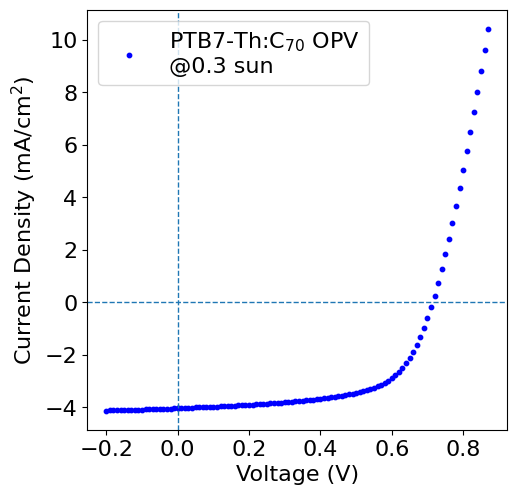

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.3 sun'
           )
#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
plt.legend()

In [ ]:
#
t0 = time.perf_counter()
#
with pm.Model() as model:
    Iph = pm.Uniform('Iph', lower=1e-4, upper=1e2 )  #mA
    Rp = pm.Uniform('Rp', lower=1e0, upper=1e8)      #Ohm
    Rs = pm.Uniform('Rs', lower=1e0, upper=1e8 )     #mOhm
    I0 = pm.Uniform('I0', lower=1e-4, upper=1e6 )    #nA
    n = pm.Uniform('n', lower=0.5, upper=500 )       #Vt(RT)=26 mV
#
    rmsd = pm.Uniform('rmsd', lower=0, upper=1e-2)
    mu = pm_I_Roberts_g(Iph, Rp, Rs, I0, n, X)
#
    y = pm.Normal('y', mu=mu, sigma=rmsd, observed=Y)
#
    trace = pm.sample(10000, tune=10000, chains=2, nuts_sampler='nutpie', target_accept=0.99)
#
t1 = time.perf_counter()
print( "elapsed time %.3f sec" % (t1-t0)  )

Progress,Draws,Divergences,Step Size,Gradients/Draw
,20000,0,0.04,255
,20000,0,0.03,63


elapsed time 729.988 sec


In [ ]:
def Roberts_g(x):
    if x <= -(np.exp(-1)):
        g = x
    elif x >= (np.exp(1)):
        g = np.log(x)
    else:
        g = -np.exp(1) + (1 + np.exp(1)) / (2 * np.exp(1)) * (x + np.exp(1))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
def I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026     #Vt(RT)=26 mV
    LogQ = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt
    return (V - nVt * (Roberts_g(LogQ) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def calcI(Iph, Rp, Rs, I0, n, V):
    V_list = V.tolist()
    I_list = [I_Roberts_g(Iph, Rp, Rs, I0, n, item) for item in V_list]
    return np.array(I_list)

In [ ]:
az.summary(trace).style.format("{:.2e}")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
I0,4.06e+00,9.43e-01,2.50e+00,5.91e+00,2.20e-02,1.80e-02,1.80e+03,2.24e+03,1.00e+00
Iph,4.05e+00,6.00e-03,4.04e+00,4.07e+00,0.00e+00,0.00e+00,8.70e+03,1.15e+04,1.00e+00
Rp,1.18e+03,3.37e+01,1.12e+03,1.25e+03,5.57e-01,3.13e-01,3.67e+03,6.85e+03,1.00e+00
Rs,8.00e+03,1.21e+02,7.76e+03,8.22e+03,2.68e+00,1.74e+00,2.02e+03,2.94e+03,1.00e+00
n,2.01e+00,3.30e-02,1.95e+00,2.07e+00,1.00e-03,1.00e-03,1.80e+03,2.21e+03,1.00e+00
rmsd,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.30e+04,1.22e+04,1.00e+00


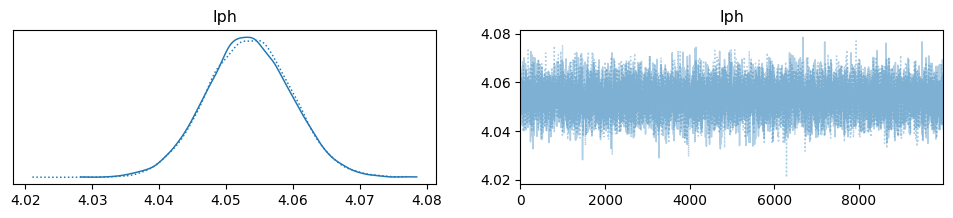

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Iph'))

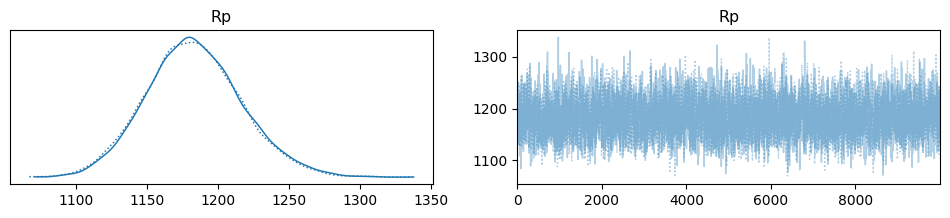

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rp'))

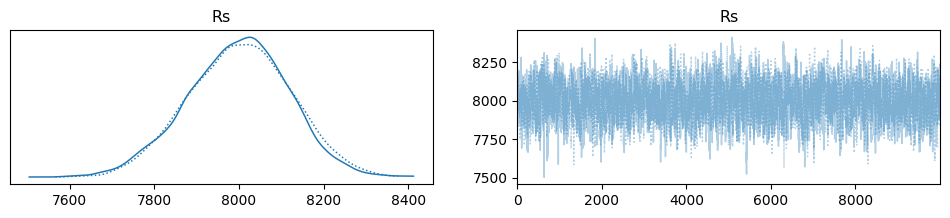

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rs'))

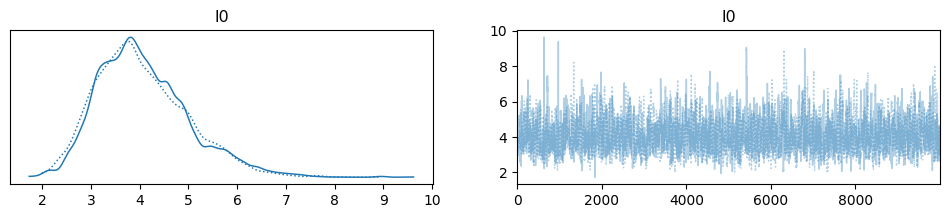

In [ ]:
with model:
  az.plot_trace(trace, var_names=('I0'))

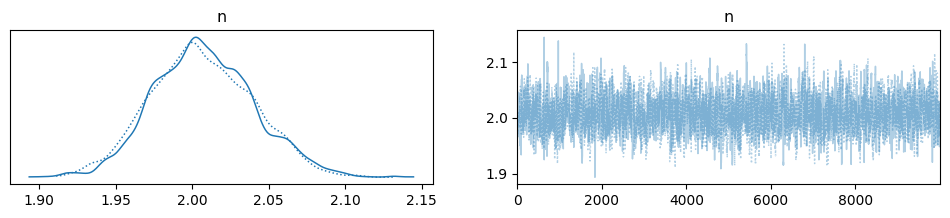

In [ ]:
with model:
  az.plot_trace(trace, var_names=('n'))

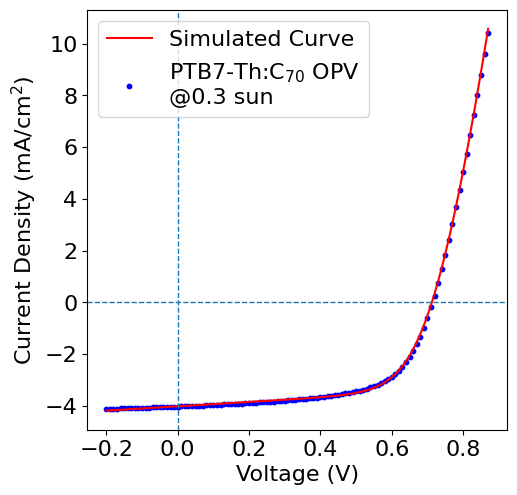

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.3 sun'
           )

xmin = np.amin(X)
xmax = np.amax(X)
N = 100
X_range = np.linspace(xmin, xmax, num=N, endpoint=True )

Q = az.summary(trace)
Iph_m = Q.loc['Iph','mean']
Rp_m = Q.loc['Rp','mean']
Rs_m = Q.loc['Rs','mean']
I0_m = Q.loc['I0','mean']
n_m = Q.loc['n','mean']
I_list = calcI(Iph_m, Rp_m, Rs_m, I0_m, n_m, X_range)

ax1.plot(X_range, I_list*1e3, color='red',
            label='Simulated Curve'
           )

#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
handles, labels = ax1.get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1])